# Model training walkthrough

This notebook follows the same path as the Prefect training flow (`train_load_areas`), but one step at a time for a single load area so you can see what each piece does and tweak it.

```text
joined parquet
    → quality gate
    → prepare_openstef_frame
    → split_chronological
    → train_area   (fit on train, rolling-score validation → MLflow run "validation")
    → refit_area   (fit on train∪validation → MLflow run "final")
    → predict_quantiles + score_forecast on the holdout
```

Source of truth lives in the package, not in notebooks:

| Step | Code |
| --- | --- |
| Config | `configs/default.yaml` → `pjm_forecasting.settings.load_settings` |
| Prepare | `pjm_forecasting.preprocessing.prepare_openstef_frame` |
| Split | `pjm_forecasting.splits.split_chronological` |
| Fit / score / predict | `pjm_forecasting.training` |
| Prefect orchestration | `pjm_forecasting.flows.training` |

OpenSTEF builds lags, calendar, and holiday features from the columns we pass. We only hand it `load` plus five weather fields. The model type is XGBoost.

**Sandbox MLflow.** Experiments write under `artifacts/notebook-experiments/` so they do not overwrite the production `final` run in `mlflow.db`. Set `USE_PRODUCTION_MLFLOW = True` only if you intend to replace that model.

**Speed.** Full 2025 validation with a 24h stride is slow (hundreds of origins). Leave `FAST = True` while iterating; flip it off when you want production-like settings.

## 0. Setup

Change `AREA`, `FAST`, and the knobs in the next cell. Knobs map to the `model:` block in `configs/default.yaml`.

In [1]:
from dataclasses import replace
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from pjm_forecasting.areas import BY_CODE
from pjm_forecasting.quality import validate_joined
from pjm_forecasting.preprocessing import OPENSTEF_COLUMNS, prepare_openstef_frame
from pjm_forecasting.settings import load_settings
from pjm_forecasting.splits import split_chronological
from pjm_forecasting.training import (
    load_area_model,
    mlflow_storage,
    predict_quantiles,
    refit_area,
    rolling_forecast,
    score_forecast,
    train_area,
    workflow_config_for_area,
)
from pjm_forecasting.utils import project_root

AREA = "AECO"
FAST = True
USE_PRODUCTION_MLFLOW = False

# Optional: score only the first N days of validation during train_area.
# None = full validation window (slow when FAST is False).
VALIDATION_SCORE_DAYS = 60 if FAST else None

base = load_settings()
root = project_root()
sandbox = root / "artifacts" / "notebook-experiments"

settings = replace(
    base,
    n_estimators=50 if FAST else base.n_estimators,
    max_day_lags=7 if FAST else base.max_day_lags,
    validation_stride=timedelta(days=7) if FAST else base.validation_stride,
)
if not USE_PRODUCTION_MLFLOW:
    settings = replace(
        settings,
        tracking_uri=f"sqlite:///{sandbox / 'mlflow.db'}",
        artifact_location=sandbox / "mlflow",
        local_artifacts_path=sandbox / "mlflow-staging",
    )

area_meta = BY_CODE[AREA]
print("area", AREA, area_meta.city, area_meta.zone)
print("tracking", settings.tracking_uri)
print("n_estimators", settings.n_estimators)
print("max_day_lags", settings.max_day_lags)
print("horizon", settings.horizon, "→", settings.horizon_timedelta)
print("quantiles", settings.quantiles)
print("validation_stride", settings.validation_stride)
print("train_end", settings.train_end, "validation_end", settings.validation_end)

/Users/mehuljain/Documents/Projects/forecast-energy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


area AECO Atlantic City AE
tracking sqlite:////Users/mehuljain/Documents/Projects/forecast-energy/artifacts/notebook-experiments/mlflow.db
n_estimators 50
max_day_lags 7
horizon PT48H → 2 days, 0:00:00
quantiles (0.1, 0.5, 0.9)
validation_stride 7 days, 0:00:00
train_end 2025-01-01 00:00:00-05:00 validation_end 2026-01-01 00:00:00-05:00


## 1. Load the joined frame

`data/processed/load_area_hourly.parquet` is the long table built by `build_load_area_frame`: metered load inner-joined to Open-Meteo **archive** weather. Notebook `01` covers how that join is formed.

In [2]:
frame_path = settings.processed_dir / "load_area_hourly.parquet"
joined = pd.read_parquet(frame_path)
print(frame_path)
print("rows", len(joined), "areas", joined["load_area"].nunique())
print("range", joined["timestamp"].min(), "→", joined["timestamp"].max())
joined.loc[joined["load_area"] == AREA].head()

/Users/mehuljain/Documents/Projects/forecast-energy/data/processed/load_area_hourly.parquet
rows 2219831 areas 29
range 2018-01-01 00:00:00-05:00 → 2026-10-06 23:00:00-04:00


,timestamp,timestamp_utc,load_area,zone,mkt_region,load,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
0,2018-01-01 00:00:00-05:00,2018-01-01 05:00:00+00:00,AECO,AE,MIDATL,1261.317,-11.6,41,5.74,0.0,1027.9
1,2018-01-01 01:00:00-05:00,2018-01-01 06:00:00+00:00,AECO,AE,MIDATL,1221.330,-11.9,42,5.94,0.0,1028.0
2,2018-01-01 02:00:00-05:00,2018-01-01 07:00:00+00:00,AECO,AE,MIDATL,1190.517,-12.1,42,5.80,0.0,1028.4
3,2018-01-01 03:00:00-05:00,2018-01-01 08:00:00+00:00,AECO,AE,MIDATL,1174.050,-12.4,43,5.66,0.0,1028.4
4,2018-01-01 04:00:00-05:00,2018-01-01 09:00:00+00:00,AECO,AE,MIDATL,1168.370,-12.6,44,5.56,0.0,1028.5


## 2. Quality gate

Same check the training flow runs before any fit. Fatal issues stop training; coverage warnings are informational.

In [3]:
report = validate_joined(joined, max_gap=settings.max_gap, load_min=settings.load_min)
report.raise_if_fatal()
print("fatal issues: none")
print("stats", report.stats)
for issue in report.issues:
    print(issue)

fatal issues: none
stats {'rows': 2219831, 'coverage': 0.999991, 'longest_gap_hours': 2.0, 'missing_hours': 20, 'start': '2018-01-01T05:00:00+00:00', 'end': '2026-10-07T03:00:00+00:00'}


## 3. Prepare the OpenSTEF frame

`prepare_openstef_frame` keeps one area, sets a US/Eastern hourly index, and drops identifiers (`load_area`, `zone`, `mkt_region`) so OpenSTEF does not treat them as features.

Columns we pass in:

- target: `load`
- predictors: temperature, humidity, wind, radiation, pressure

OpenSTEF then adds lags (up to `max_day_lags`), calendar fields, and US holidays (`country_code`).

In [4]:
prepared = prepare_openstef_frame(joined, AREA)
print("columns", list(prepared.columns))
print("expected", list(OPENSTEF_COLUMNS))
print("index tz", prepared.index.tz)
print("shape", prepared.shape)
print("nulls")
print(prepared.isna().sum())
prepared.head()

columns ['load', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'shortwave_radiation', 'surface_pressure']
expected ['load', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'shortwave_radiation', 'surface_pressure']
index tz US/Eastern
shape (76823, 6)
nulls
load                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
shortwave_radiation     0
surface_pressure        0
dtype: int64


,load,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
timestamp,,,,,,
2018-01-01 00:00:00-05:00,1261.317,-11.6,41,5.74,0.0,1027.9
2018-01-01 01:00:00-05:00,1221.330,-11.9,42,5.94,0.0,1028.0
2018-01-01 02:00:00-05:00,1190.517,-12.1,42,5.80,0.0,1028.4
2018-01-01 03:00:00-05:00,1174.050,-12.4,43,5.66,0.0,1028.4
2018-01-01 04:00:00-05:00,1168.370,-12.6,44,5.56,0.0,1028.5


## 4. Chronological split

Half-open Eastern boundaries from config:

| Window | Rule | Default use |
| --- | --- | --- |
| train | `index < train_end` | Fit for the `validation` MLflow run |
| validation | `train_end ≤ index < validation_end` | Rolling score, then included in `refit` |
| test | `index ≥ validation_end` | Holdout only — **not** used by the Prefect fit/refit |

OpenSTEF's own splitter is disabled (`val_fraction=0`, `test_fraction=0`); these windows are authoritative.

In [5]:
split = split_chronological(prepared, settings.train_end, settings.validation_end)

def _window_summary(name, frame):
    return {
        "window": name,
        "rows": len(frame),
        "start": frame.index.min(),
        "end": frame.index.max(),
        "load_mean": float(frame["load"].mean()),
    }

summary = pd.DataFrame(
    [
        _window_summary("train", split.train),
        _window_summary("validation", split.validation),
        _window_summary("test", split.test),
    ]
)
summary

,window,rows,start,end,load_mean
0,train,61368,2018-01-01 00:00:00-05:00,2024-12-31 23:00:00-05:00,1058.759842
1,validation,8760,2025-01-01 00:00:00-05:00,2025-12-31 23:00:00-05:00,1041.715238
2,test,6695,2026-01-01 00:00:00-05:00,2026-10-06 23:00:00-04:00,1098.081563


Optionally shorten the validation frame used inside `train_area` so rolling forecasts finish faster while the train set stays full.

In [6]:
train_df = split.train
validation_df = split.validation
if VALIDATION_SCORE_DAYS is not None:
    cutoff = validation_df.index.min() + pd.Timedelta(days=VALIDATION_SCORE_DAYS)
    validation_df = validation_df.loc[validation_df.index < cutoff]
    print(
        "scoring validation",
        validation_df.index.min(),
        "→",
        validation_df.index.max(),
        f"({len(validation_df)} rows)",
    )
else:
    print("scoring full validation window", len(validation_df), "rows")

scoring validation 2025-01-01 00:00:00-05:00 → 2025-03-01 23:00:00-05:00 (1440 rows)


## 5. What OpenSTEF is configured with

`workflow_config_for_area` is the bridge from our YAML settings to OpenSTEF's `ForecastingWorkflowConfig`. The only XGBoost hyperparameter we currently set is `n_estimators`. Everything else uses OpenSTEF defaults unless you extend `training.workflow_config_for_area`.

In [7]:
storage = mlflow_storage(settings)
config = workflow_config_for_area(
    area_meta,
    settings,
    storage,
    run_name="validation",
    reuse=False,
)

knobs = {
    "model_id": config.model_id,
    "model": config.model,
    "horizons": [str(h) for h in config.horizons],
    "quantiles": [float(q) for q in config.quantiles],
    "target_column": config.target_column,
    "temperature_column": config.temperature_column,
    "relative_humidity_column": config.relative_humidity_column,
    "wind_speed_column": config.wind_speed_column,
    "radiation_column": config.radiation_column,
    "pressure_column": config.pressure_column,
    "predict_history": config.predict_history,
    "cutoff_history": config.cutoff_history,
    "max_day_lags": config.max_day_lags,
    "country_code": str(config.location.country_code),
    "coordinate": (float(config.location.coordinate.latitude), float(config.location.coordinate.longitude)),
    "n_estimators": settings.n_estimators,
    "data_splitter": {
        "val_fraction": config.data_splitter.val_fraction,
        "test_fraction": config.data_splitter.test_fraction,
    },
}
knobs

{'model_id': 'pjm-AECO',
 'model': 'xgboost',
 'horizons': ['P2D'],
 'quantiles': [0.1, 0.5, 0.9],
 'target_column': 'load',
 'temperature_column': 'temperature_2m',
 'relative_humidity_column': 'relative_humidity_2m',
 'wind_speed_column': 'wind_speed_10m',
 'radiation_column': 'shortwave_radiation',
 'pressure_column': 'surface_pressure',
 'predict_history': datetime.timedelta(days=14),
 'cutoff_history': datetime.timedelta(days=14),
 'max_day_lags': 7,
 'country_code': 'US',
 'coordinate': (39.3643, -74.4229),
 'n_estimators': 50,
 'data_splitter': {'val_fraction': 0.0, 'test_fraction': 0.0}}

### Knobs worth tweaking

| Knob | Where | Effect |
| --- | --- | --- |
| `n_estimators` | YAML `model.n_estimators` or `replace(...)` | Trees in the XGBoost ensemble; main speed/accuracy tradeoff |
| `max_day_lags` | YAML / `replace` | How many days of load lag features OpenSTEF builds |
| `predict_history_days` / `cutoff_history_days` | YAML | History windows around each origin |
| `quantiles` | YAML | Which predictive quantiles are trained (default P10/P50/P90) |
| `horizon` / `prediction_length` | YAML | Forecast length (default 48h) |
| `validation_stride_hours` | YAML | Spacing of rolling validation origins |
| `splits.train_end` / `validation_end` | YAML | Chronological boundaries |
| Extra XGB params | Code in `workflow_config_for_area` | Learning rate, depth, etc. — not exposed in YAML yet |

Feature set changes (new weather vars, engineered columns) start in the joined parquet / `prepare_openstef_frame`, then need matching column wiring in `workflow_config_for_area`.

## 6. Fit + rolling validation (`train_area`)

This is the interactive version of the flow's `fit_area` task:

1. Fit XGBoost on `train` (validation frame is passed through to OpenSTEF as `data_val`).
2. Walk origins every `validation_stride` across the validation window.
3. At each origin, mask `load` after the origin (weather stays) and predict 48h.
4. Score with MAE / RMSE / pinball / P10–P90 coverage.
5. Store the MLflow run named `validation`.

First run can take a few minutes even in `FAST` mode.

In [8]:
trained = train_area(
    AREA,
    train_df,
    validation_df,
    settings=settings,
    storage=storage,
)
trained

{'load_area': 'AECO',
 'model_id': 'pjm-AECO',
 'run_id': 'd2c58e0b61d041fb8cfcdfaba3701238',
 'run_name': 'validation',
 'metrics': {'n': 432.0,
  'mae': 47.801685063114874,
  'rmse': 61.71397726820766,
  'pinball_p10': 12.16018193653248,
  'pinball_p50': 23.900842531557437,
  'pinball_p90': 18.019252656385635,
  'coverage_p10_p90': 0.5393518518518519}}

In [9]:
pd.Series(trained["metrics"], name="validation_rolling").to_frame("value")

,value
n,432.000000
mae,47.801685
rmse,61.713977
pinball_p10,12.160182
pinball_p50,23.900843
pinball_p90,18.019253
coverage_p10_p90,0.539352


### Peek at one validation origin

Reload the `validation` MLflow run and plot the first 48h forecast against actuals.

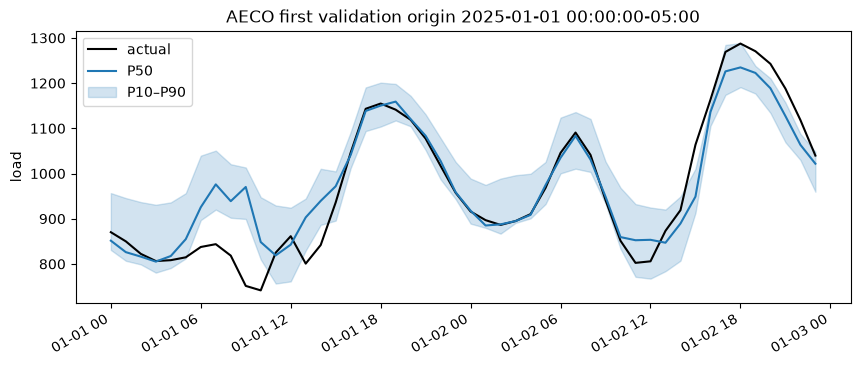

{'n': 48.0,
 'mae': 36.92756619262695,
 'rmse': 58.04208911446869,
 'pinball_p10': 13.853990561930337,
 'pinball_p50': 18.463783096313474,
 'pinball_p90': 11.924883797200517,
 'coverage_p10_p90': 0.7291666666666666}

In [10]:
from openstef_models.presets import create_forecasting_workflow

# Reload the validation run we just wrote (reuse=True, run_name=validation).
val_config = workflow_config_for_area(
    area_meta,
    settings,
    storage,
    run_name="validation",
    reuse=True,
)
val_workflow = create_forecasting_workflow(val_config)

history_for_val = pd.concat([train_df, validation_df]).sort_index()
origin = validation_df.index.min()
sample = rolling_forecast(
    val_workflow,
    history_for_val,
    start=origin,
    end=origin + settings.horizon_timedelta,
    settings=replace(settings, validation_stride=settings.horizon_timedelta),
)

actual = validation_df["load"].reindex(sample.index)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(actual.index, actual.values, label="actual", color="black", linewidth=1.5)
ax.plot(sample.index, sample["quantile_P50"], label="P50", color="C0")
if {"quantile_P10", "quantile_P90"}.issubset(sample.columns):
    ax.fill_between(
        sample.index,
        sample["quantile_P10"],
        sample["quantile_P90"],
        color="C0",
        alpha=0.2,
        label="P10–P90",
    )
ax.set_title(f"{AREA} first validation origin {origin}")
ax.set_ylabel("load")
ax.legend()
fig.autofmt_xdate()
plt.show()
score_forecast(validation_df["load"], sample)

## 7. Refit on train ∪ validation (`refit_area`)

Production predictions reload the MLflow run named `final`. That run is **not** the validation fit — it is a refit on everything before the test window so the deployed model sees 2025 as well.

Use the **full** validation frame here (not the shortened scoring slice), matching the training flow.

In [11]:
final = refit_area(
    AREA,
    split.train,
    split.validation,
    settings=settings,
    storage=storage,
)
final

{'load_area': 'AECO',
 'model_id': 'pjm-AECO',
 'run_id': 'eacd4a9e50254677a4f0c4edd82fdeaf',
 'run_name': 'final'}

## 8. Holdout score on the test window

Reload `final`, forecast from the first test timestamp, score against actuals. This still uses **archive** weather on the holdout, so it is optimistic relative to a real published forecast. For leakage-safe weather, use notebook `02` (Beam backtest).

In [12]:
history = pd.concat([split.train, split.validation, split.test]).sort_index()
origin = split.test.index.min()
workflow = load_area_model(AREA, settings=settings, storage=storage)
forecast = predict_quantiles(
    AREA,
    history,
    origin,
    workflow=workflow,
    settings=settings,
)
holdout = score_forecast(split.test["load"], forecast)
holdout

{'n': 48.0,
 'mae': 51.99775335693359,
 'rmse': 74.11502416472054,
 'pinball_p10': 12.877154184977217,
 'pinball_p50': 25.998876678466797,
 'pinball_p90': 11.93903856913249,
 'coverage_p10_p90': 0.6458333333333334}

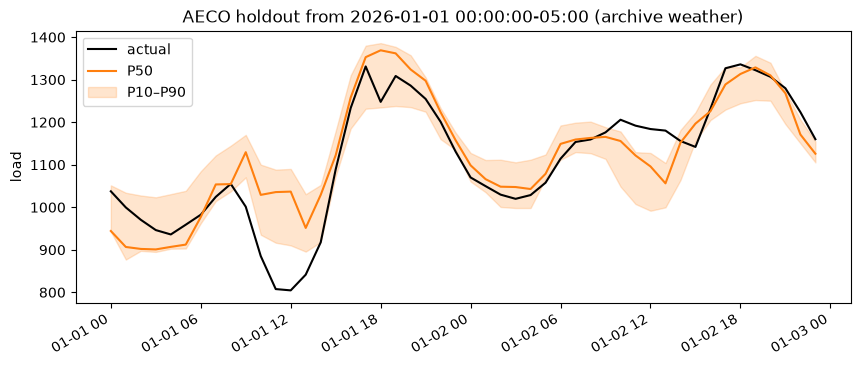

In [13]:
actual = split.test["load"].reindex(forecast.index)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(actual.index, actual.values, label="actual", color="black", linewidth=1.5)
ax.plot(forecast.index, forecast["quantile_P50"], label="P50", color="C1")
if {"quantile_P10", "quantile_P90"}.issubset(forecast.columns):
    ax.fill_between(
        forecast.index,
        forecast["quantile_P10"],
        forecast["quantile_P90"],
        color="C1",
        alpha=0.2,
        label="P10–P90",
    )
ax.set_title(f"{AREA} holdout from {origin} (archive weather)")
ax.set_ylabel("load")
ax.legend()
fig.autofmt_xdate()
plt.show()

## 9. Tweak loop

Change one knob, retrain, compare metrics. Keep the sandbox MLflow URI so production stays untouched.

Ideas to try:

- more/fewer trees: `n_estimators=200` vs `50`
- longer/shorter lag memory: `max_day_lags=21` vs `7`
- denser validation origins: `validation_stride=timedelta(hours=24)` (slower, more honest)
- different area: set `AREA = "PEPCO"` in section 0 and re-run from the top

In [15]:
candidate = replace(
    settings,
    n_estimators=500,
    max_day_lags=21,
)

compare_storage = mlflow_storage(candidate)
compare = train_area(
    AREA,
    train_df,
    validation_df,
    settings=candidate,
    storage=compare_storage,
)

comparison = pd.DataFrame(
    {
        "baseline_fast": trained["metrics"],
        "candidate": compare["metrics"],
    }
).T
comparison

,n,mae,rmse,pinball_p10,pinball_p50,pinball_p90,coverage_p10_p90
baseline_fast,432.0,47.801685,61.713977,12.160182,23.900843,18.019253,0.539352
candidate,432.0,44.674804,57.920152,10.843911,22.337402,17.377524,0.409722


## 10. Promote a change into the real pipeline

When a tweak looks good:

1. Put the new values in `configs/default.yaml` (or extend `workflow_config_for_area` for params YAML cannot express).
2. Retrain for real (writes production MLflow `final`):

```bash
python -c "from pjm_forecasting.flows.training import train_load_areas; train_load_areas(areas='AECO')"
```

3. Re-check holdout in this notebook with `USE_PRODUCTION_MLFLOW = True`, or run notebook `02` for a Beam (point-in-time weather) score.

Remember: archive-weather holdout ≠ operational skill. Beam is the stricter test.